In [1]:
!git clone https://github.com/olit2004/modern_AI.git /content/modern_AI || (cd /content/modern_AI && git pull)
%cd /content/modern_AI/recursive_learning



Cloning into '/content/modern_AI'...
remote: Enumerating objects: 215, done.
remote: Counting objects: 100% (215/215), done.
remote: Compressing objects: 100% (151/151), done.
remote: Total 215 (delta 98), reused 178 (delta 61), pack-reused 0 (from 0)
Receiving objects: 100% (215/215), 11.88 MiB | 24.67 MiB/s, done.
Resolving deltas: 100% (98/98), done.
/content/modern_AI/recursive_learning


In [2]:
# Build high-speed Pascal Pons C++ Bitboard Solver & fetch opening book
!make -C src/solver/cpp/pons
!test -f src/solver/cpp/pons/7x6.book || curl -L -o src/solver/cpp/pons/7x6.book https://github.com/PascalPons/connect4/releases/download/book/7x6_small.book

# Run test suite
!PYTHONPATH=. pytest tests/ -v


make: Entering directory '/content/modern_AI/recursive_learning/src/solver/cpp/pons'
g++ --std=c++11 -W -Wall -O3 -DNDEBUG -MM Solver.cpp > ./.depend
g++ --std=c++11 -W -Wall -O3 -DNDEBUG   -c -o Solver.o Solver.cpp
g++ --std=c++11 -W -Wall -O3 -DNDEBUG   -c -o main.o main.cpp
g++ --std=c++11 -W -Wall -O3 -DNDEBUG  -o c4solver main.o Solver.o 
make: Leaving directory '/content/modern_AI/recursive_learning/src/solver/cpp/pons'
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 6144k  100 6144k    0     0  12.5M      0 --:--:-- --:--:-- --:--:-- 12.5M
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/modern_AI/recursive_learning
plugins: platformdirs

In [3]:
# 1. Run both Verified (with Solver Judge) and Unverified (without Judge) under strict parity
!python run_experiments.py \
    --config configs/self_learning.yaml \
    --condition compare \
    --out /content/results \
    --clean \
    --require_cpp \
    --final





[Platform] Running on: COLAB
[Output] Results will be written to: /content/results
[Solver Engine] ACTIVE: Pascal Pons C++ Bitboard Solver (c4solver, with 7x6 opening book)
[Data] Generating position pool and zero-leakage splits in data...
[Data] Generated: 2109 train, 452 dev, 453 test positions.

Running Condition: v3_verified | Seed: 42
[verified] Running Round 0: Initial baseline training...
[Reference] Random Player Dev: Strict=26.99% | Outcome=44.03%
[Reference] Heuristic Player Dev: Strict=61.28% | Outcome=68.81%
[verified] Starting Round 1...
[verified] Round 1 Mistake Mining: 1050 blunders/suboptimal + 450 optimal positions (Total: 1500)
[verified] Round 1 STRICTLY ACCEPTED! Dev agreement: 0.619 (prev: 0.608)
[verified] Starting Round 2...
[verified] Round 2 Mistake Mining: 1050 blunders/suboptimal + 450 optimal positions (Total: 1500)
[verified] Round 2 STRICTLY ACCEPTED! Dev agreement: 0.637 (prev: 0.619)
[verified] Starting Round 3...
[verified] Round 3 Mistake Mining: 841 

[Demo] Found unverified (without judge) metrics: /content/results/v2_unverified_seed42/experiment_metrics.json

1. ACCEPTED & REJECTED ROUNDS SUMMARY TABLE
Round   | Status             | Strict Agree | Outcome Agree | vs Random | vs Heuristic | vs Minimax | Examples
--------------------------------------------------------------------------------------------------
R0      | ACCEPTED_BASELINE  | 60.8%        | 72.1%         | 98%       | 41%          | 29%        | 1500    
R1      | ACCEPTED           | 61.9%        | 72.6%         | 96%       | 52%          | 46%        | 3000    
R2      | ACCEPTED           | 63.7%        | 73.7%         | 99%       | 47%          | 37%        | 4500    
R3      | ACCEPTED           | 63.9%        | 73.0%         | 98%       | 55%          | 34%        | 6000    

 [Chart] Saved progress figure to: /content/results/figures/demo_progress.png

⚔️  2. LIVE HEAD-TO-HEAD MATCH: Round 3 vs Round 0 (100 Games with Randomized Openings)
  Round 3 (Improved): 

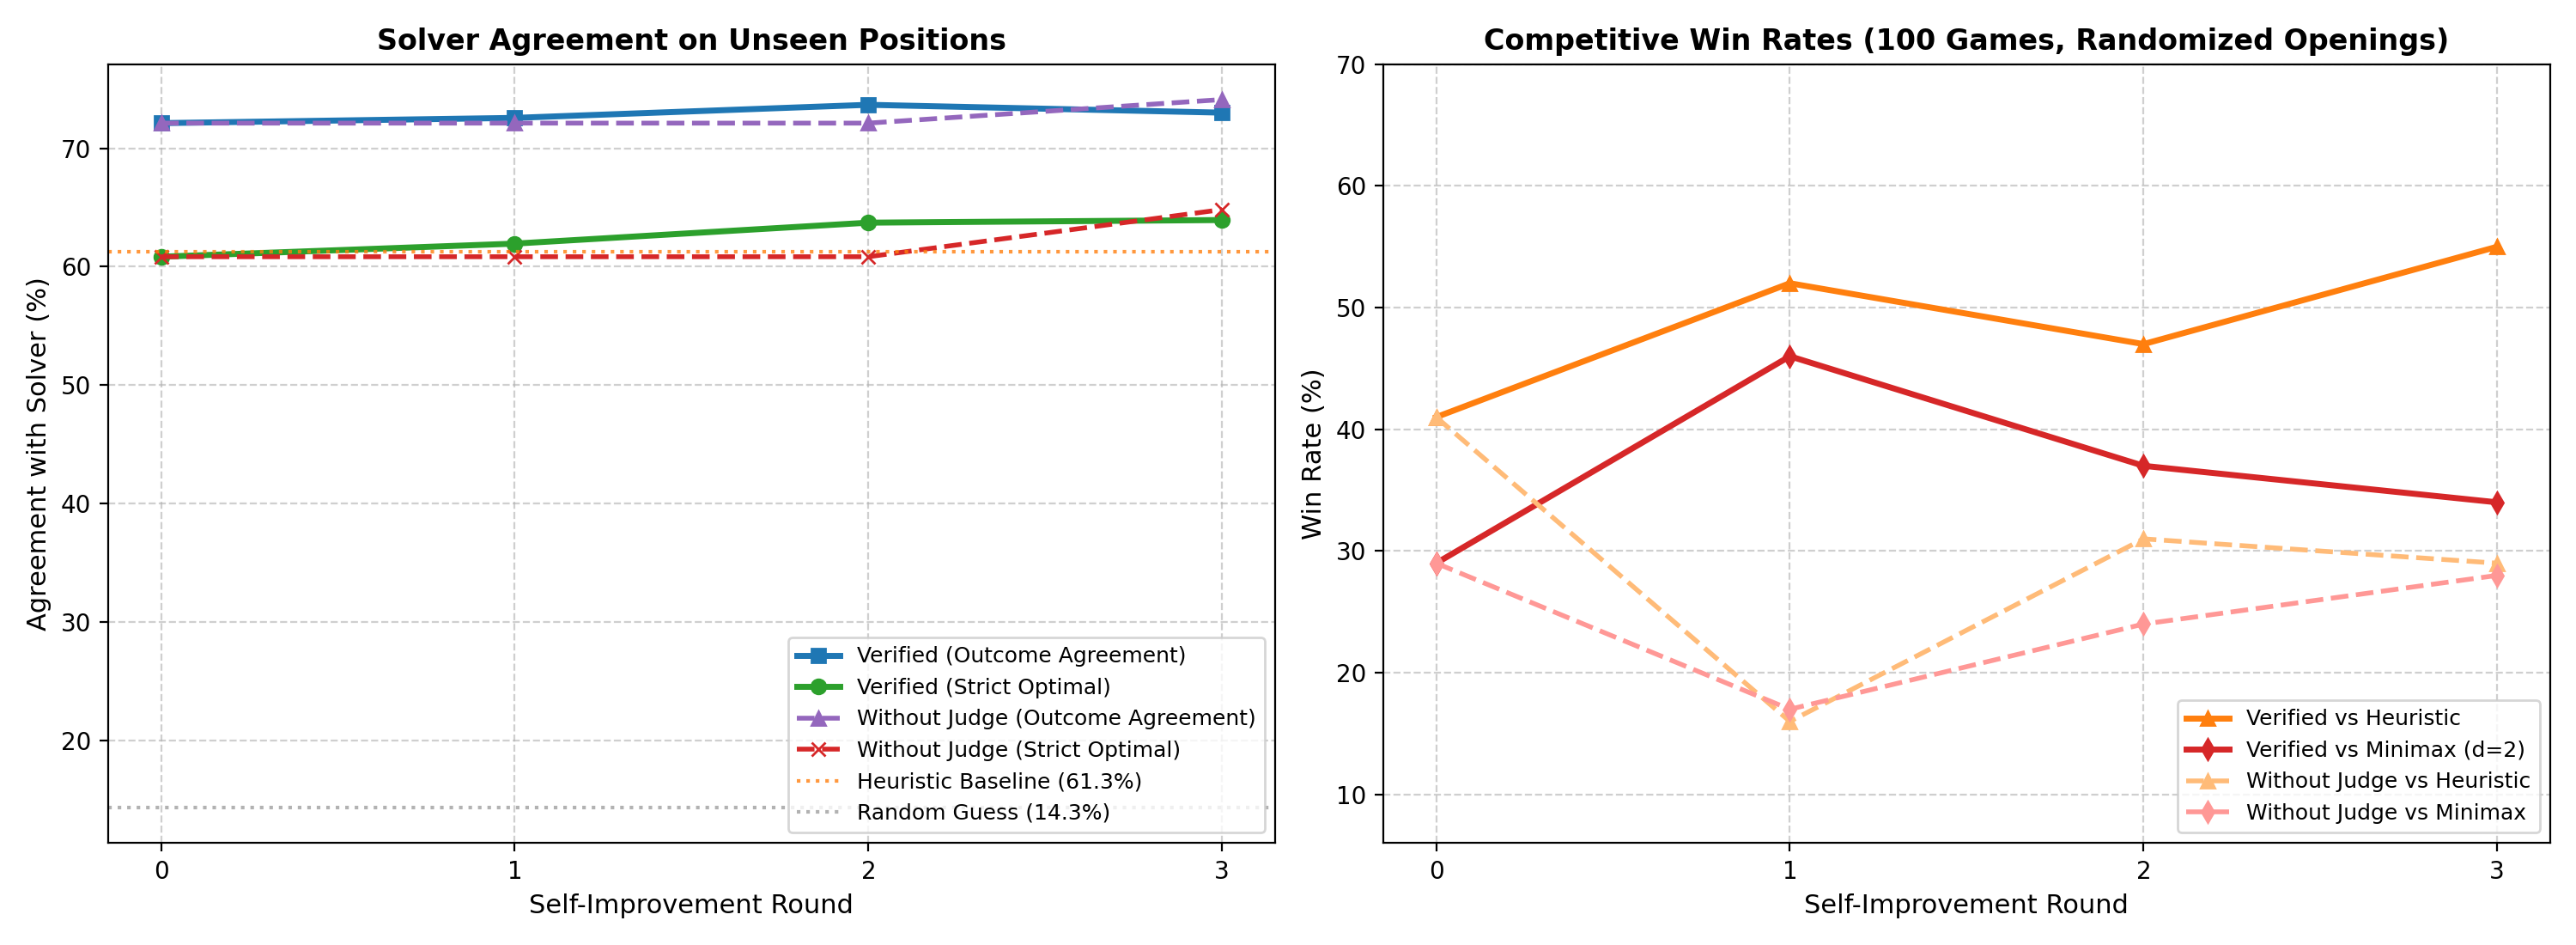

In [4]:
# 2. Render comparative progress curves and blunder showdown
!python demo.py --results_dir /content/results --num_games 100

from IPython.display import Image, display
display(Image(filename="/content/results/figures/demo_progress.png"))
